In [1]:
%run ../base.ipynb

mare


#### noise structure



Let's inspect a different noise structure, namely a Bernoullian one that *multiplies* the output $y$ with a small probability $1-p$, and see whether the resulting graphs change. 



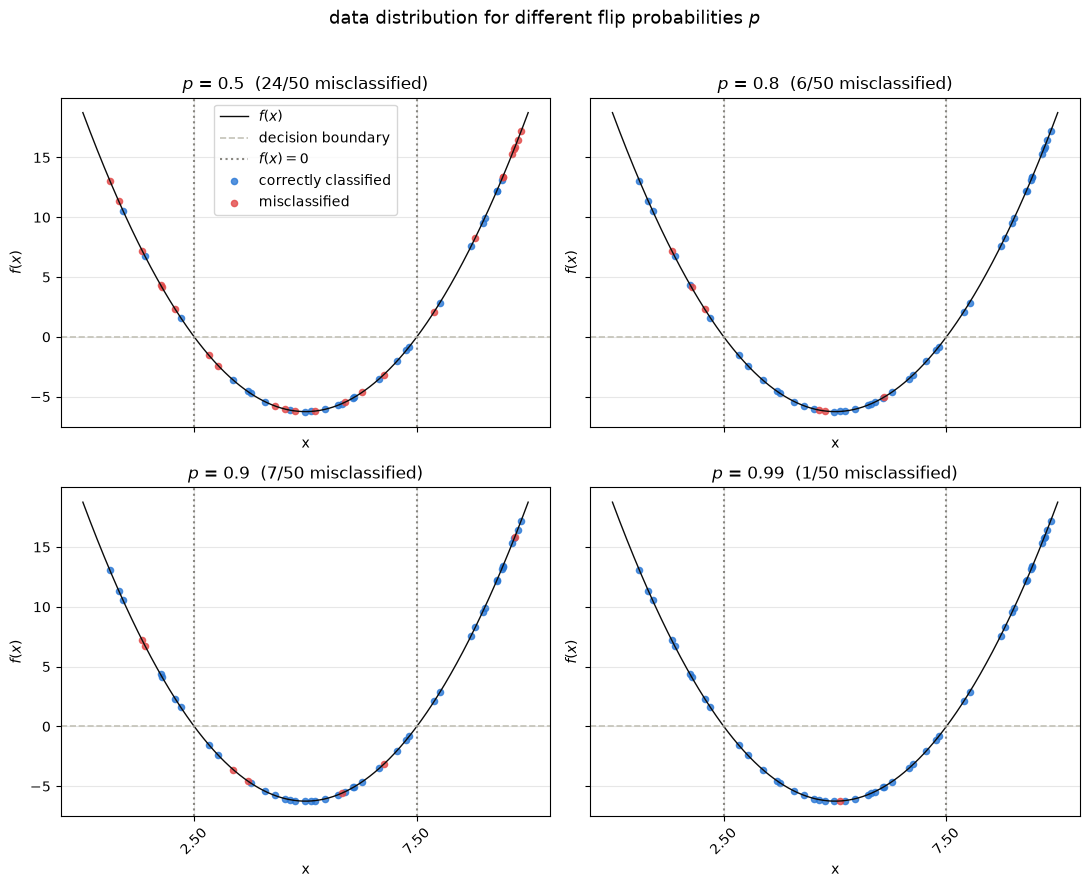

In [2]:
# DEFAULT PARAMETERS, shared by all the experiments below
# MODEL
mymodel = DecisionTreeClassifier

# PARAMETERS
supp_size = 10_000
data_size_test = 200_000
data_size_tr = 50
noise_std = 5
num_iter = 100

explore_data(f=centered_parabola, n=data_size_tr, N=supp_size,
             error_type='bernoulli', probs=(0.5, 0.8, 0.9, 0.99))

### test error for a heuristic $p = 0.8$

[checkpoint] bound: "unionbound" -> union_bound, params: []


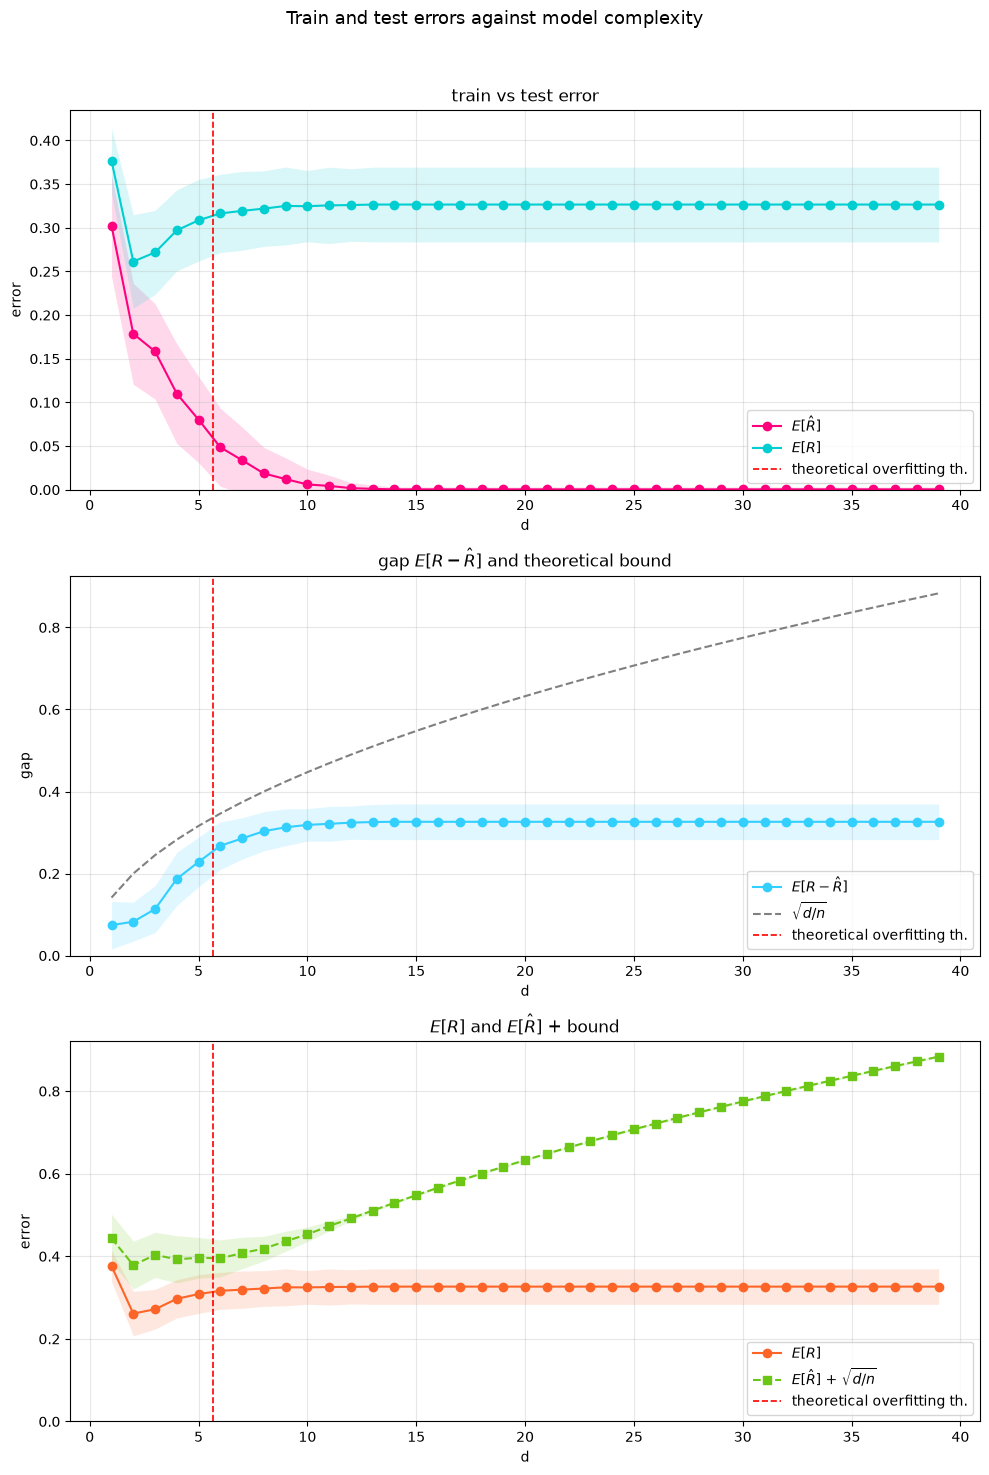

In [3]:
prob = 0.8

# build test set
x_test = sample_x(data_size_test, supp_size)
y_test = sample_y_bernoulli(x=x_test, f=centered_parabola, p=prob)

# build models and do plots
hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n=data_size_tr, sigma=noise_std, T=num_iter, model=mymodel,
    noise_type='bernoulli', p=prob, N=supp_size)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps,
      n=data_size_tr, sigma=noise_std, T=num_iter, model=mymodel,
      bound_name="unionbound", bound_params={},
      noise_type='bernoulli', p=prob)

In [4]:
# show animated function

animation = animate_learned_function(model = mymodel, n = data_size_tr, best_pred = predictions,
                         best_x = x, best_y = y, x_grid = x_grid)
HTML(animation.to_jshtml())

la differenza con un errore bernoulliano è solo che abbiamo piu noise difficile da prevedere, ma l'andamento delle curve è lo stesso. 

vediamo allora cosa succede ai dati con diverse noise structures, perché secondo me la differenza di comportamento di cui sopra dipende solo dal num di misclassified inputs


### which $\sigma^*$ gives the same misclassified inputs as $p = 0.8$?

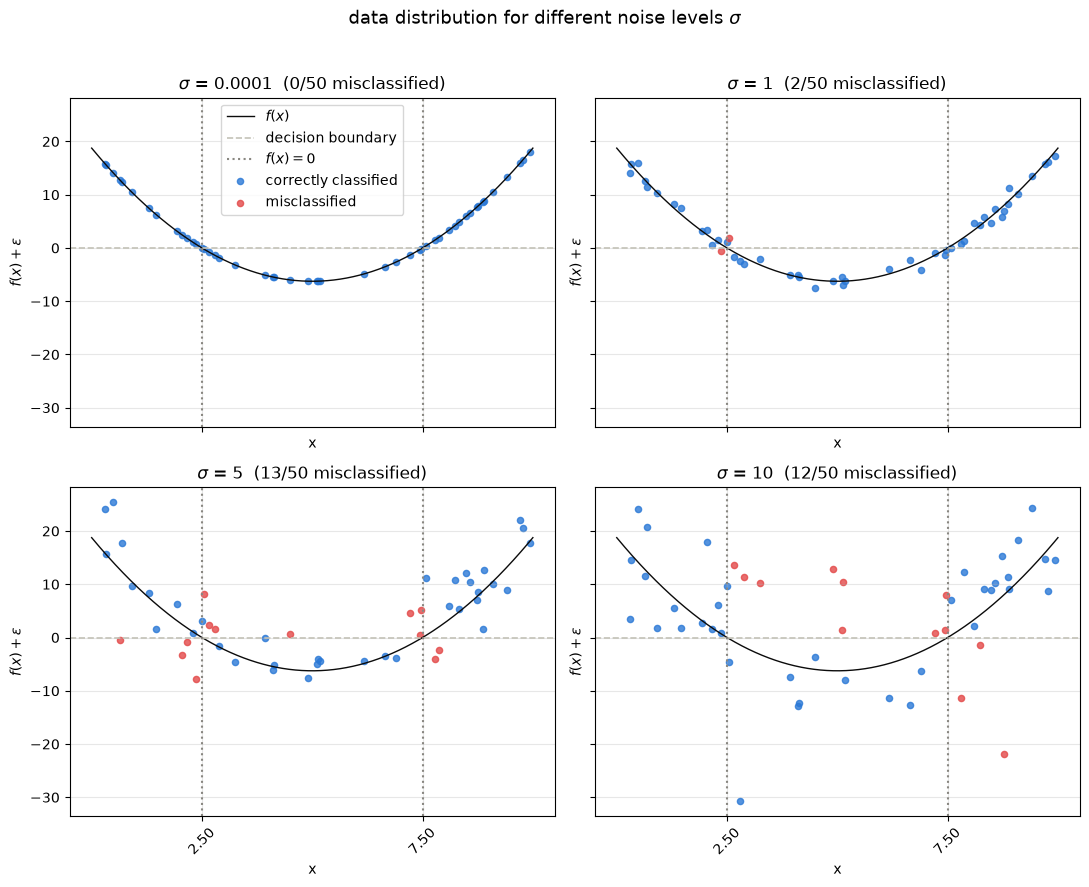

In [5]:
# explore data for gaussian noise
explore_data(f=centered_parabola, n=data_size_tr, N=supp_size, sigmas=(10**(-4), 1, 5, 10))

one sample is too noisy to compare the two noise structures: for a grid of $\sigma$, average the fraction of misclassified inputs over $100$ training samples of size $n$, and take as $\sigma^*$ the one closest to $1 - p$, the fraction flipped by bernoulli noise.

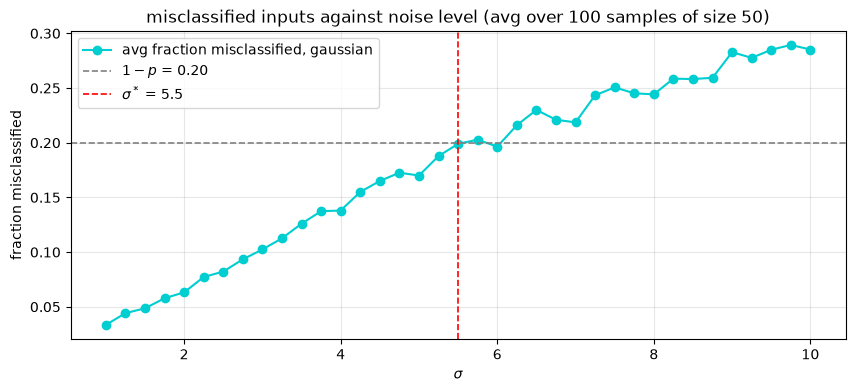

sigma* = 5.5


In [6]:
# PARAMETERS (on top of the defaults)
prob = 0.8
num_samples = 100

sigma_star = find_sigma_star(f=centered_parabola, p=prob, n=data_size_tr, N=supp_size, num_samples=num_samples)
print(f'sigma* = {sigma_star}')

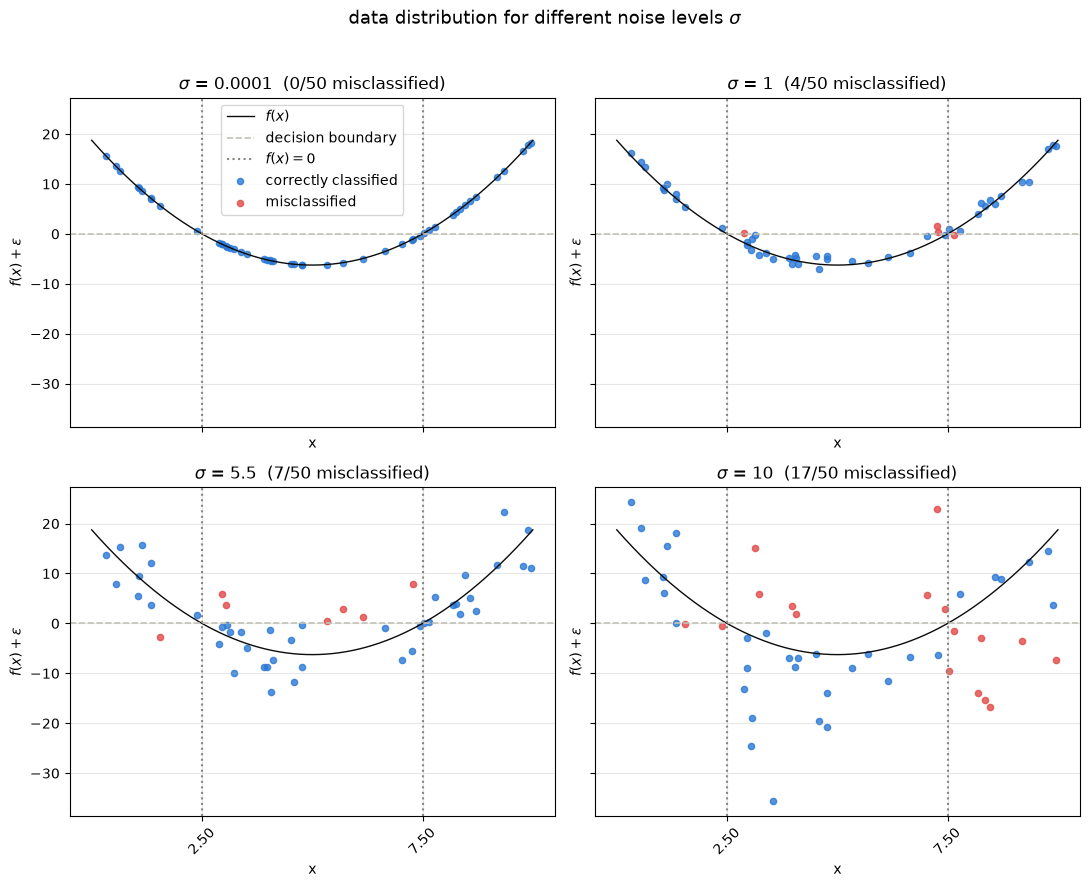

In [7]:
# explore data for gaussian noise, around sigma*
explore_data(f=centered_parabola, n=data_size_tr, N=supp_size, sigmas=(10**(-4), 1, sigma_star, 10))

### test error for $p = 0.8$ and $\sigma = \sigma^*$

[checkpoint] bound: "unionbound" -> union_bound, params: []


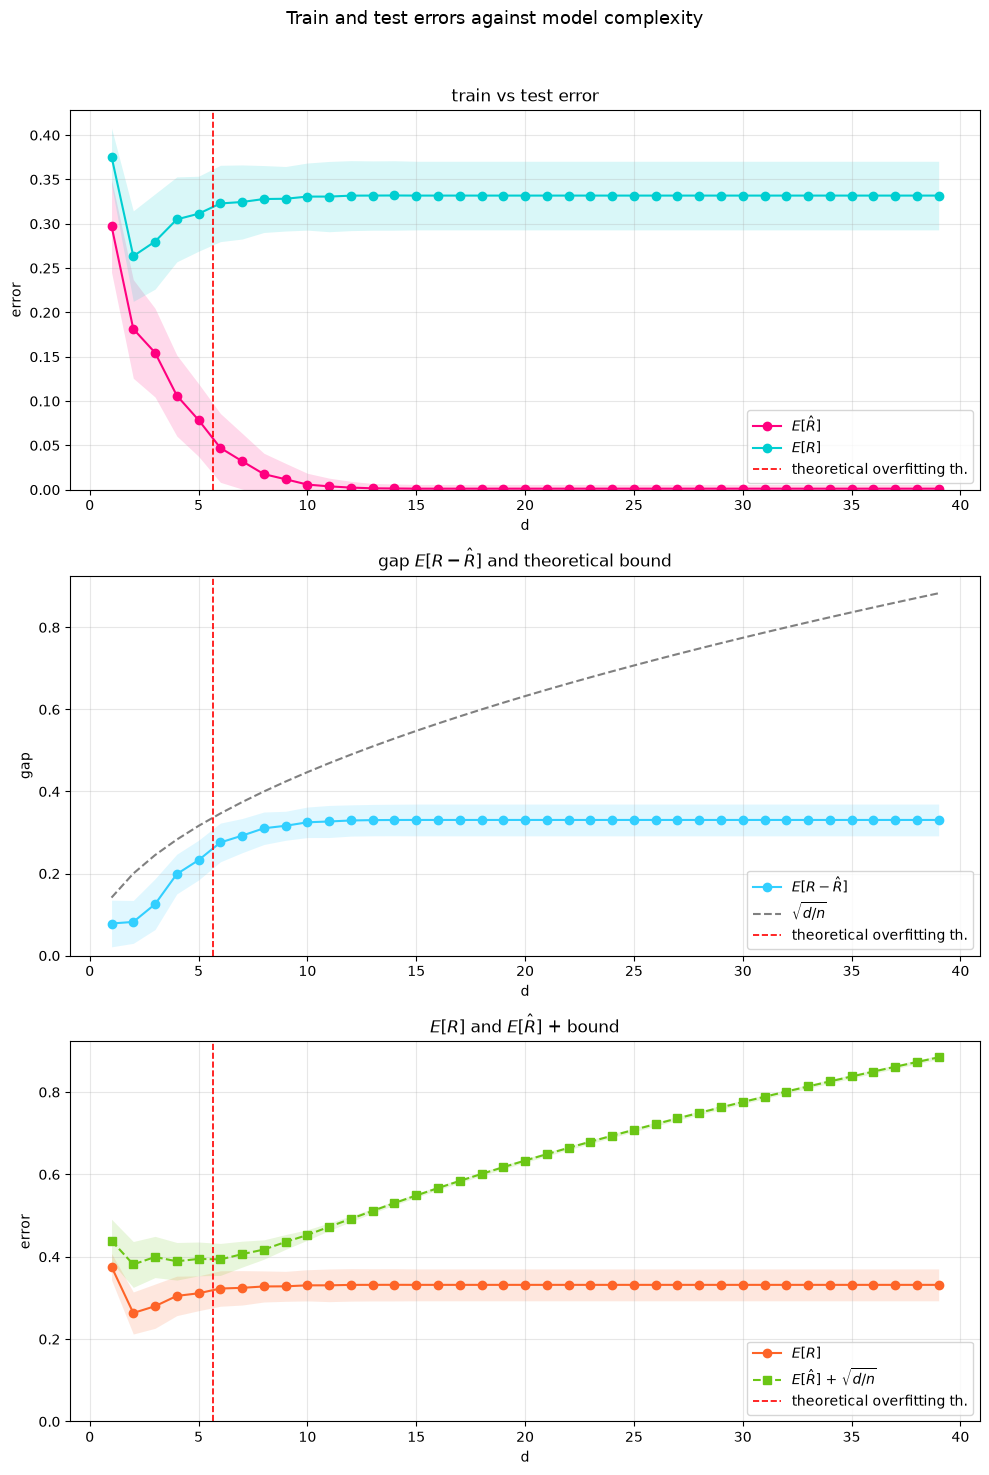

In [8]:
# build test set
x_test = sample_x(data_size_test, supp_size)
y_test = sample_y_bernoulli(x=x_test, f=centered_parabola, p=prob)

# build models and do plots
hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n=data_size_tr, sigma=noise_std, T=num_iter, model=mymodel,
    noise_type='bernoulli', p=prob, N=supp_size)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps,
      n=data_size_tr, sigma=noise_std, T=num_iter, model=mymodel,
      bound_name="unionbound", bound_params={},
      noise_type='bernoulli', p=prob)

[checkpoint] bound: "unionbound" -> union_bound, params: []


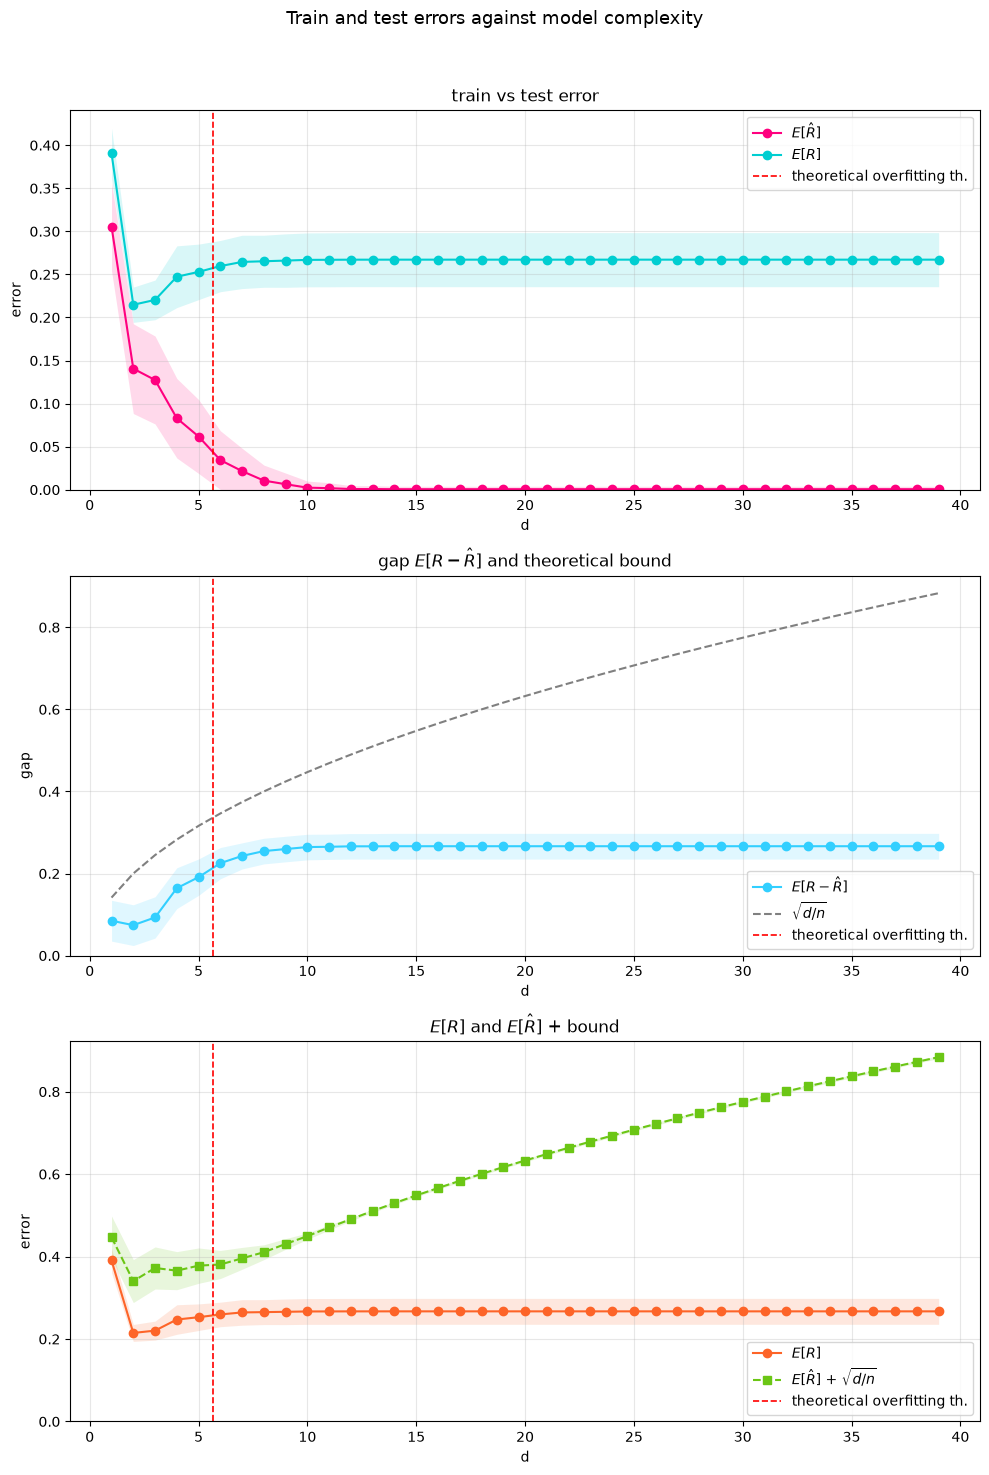

In [9]:
# build test set
x_test = sample_x(data_size_test, supp_size)
y_test = sample_y(x=x_test, f=centered_parabola, sigma=sigma_star)

# build models and do plots
hat_Rs, Rs, gaps, std_hat_Rs, std_Rs, std_gaps, predictions, x, y, x_grid = main_loop(
    x_test, y_test, n=data_size_tr, sigma=sigma_star, T=num_iter, model=mymodel,
    noise_type='gaussian', p=prob, N=supp_size)
plots(hat_Rs, Rs, gaps, std_hat_Rs=std_hat_Rs, std_Rs=std_Rs, std_gaps=std_gaps,
      n=data_size_tr, sigma=sigma_star, T=num_iter, model=mymodel,
      bound_name="unionbound", bound_params={},
      noise_type='gaussian', p=prob)

$\star$ They are essentially equal!!! hehehehhe $\star$